# Домашка

## Часть A — Domain shift / распределения
1) Выберите датасет на русском  языке и два домена (2 темы из одного датасета, или 2 датасета HF, или свои тексты. Вариант датасета: https://huggingface.co/datasets/data-silence/rus_news_classifier).
2) Посчитайте **top-30 log-odds** токенов (в обе стороны).
3) Нарисуйте хотя бы 2 графика распределений (на выбор):
   - длина документов,
   - Zipf (частоты топ-100 токенов),
   - доля чисел/пунктуации,
   - размер словаря.
4) добавьте лемматизацию, n-граммы, стоп-слова, и сравните важные токены.
5) Напишите 5–10 наблюдений: что изменилось и почему.



In [1]:
# Базовые библиотеки
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from collections import Counter
from typing import List, Tuple

# sklearn
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

plt.rcParams["figure.dpi"] = 140
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [2]:
TOKEN_RE = re.compile(r"[А-Яа-яЁё]+")

def simple_tokenize(text: str) -> List[str]:
    return TOKEN_RE.findall(text.lower())

def chunk_tokens(tokens: List[str], chunk_size: int = 200, min_frac: float = 0.5) -> List[str]:
    """Режем на чанки фиксированной длины; хвост сохраняем, если он >= min_frac*chunk_size."""
    chunks = []
    min_len = int(chunk_size * min_frac)
    for i in range(0, len(tokens), chunk_size):
        chunk = tokens[i:i+chunk_size]
        if len(chunk) >= min_len:
            chunks.append(" ".join(chunk))
    return chunks

def log_odds_with_smoothing(counts_a: Counter, counts_b: Counter, alpha: float = 0.1):
    """Δ(w)=log((c_a(w)+α)/(N_a+α|V|)) - log((c_b(w)+α)/(N_b+α|V|))"""
    vocab = set(counts_a) | set(counts_b)
    V = len(vocab)
    Na = sum(counts_a.values())
    Nb = sum(counts_b.values())
    deltas = {}
    for w in vocab:
        pa = (counts_a[w] + alpha) / (Na + alpha * V)
        pb = (counts_b[w] + alpha) / (Nb + alpha * V)
        deltas[w] = math.log(pa) - math.log(pb)
    return deltas

def top_log_odds_words(texts_a: List[str], texts_b: List[str], top_n: int = 25, alpha: float = 0.1):
    ca = Counter()
    cb = Counter()
    for t in texts_a:
        ca.update(simple_tokenize(t))
    for t in texts_b:
        cb.update(simple_tokenize(t))
    deltas = log_odds_with_smoothing(ca, cb, alpha=alpha)
    pos = sorted(deltas.items(), key=lambda x: x[1], reverse=True)[:top_n]
    neg = sorted(deltas.items(), key=lambda x: x[1])[:top_n]
    return pos, neg

def strip_gutenberg_header_footer(text: str) -> str:
    """Грубое (но часто рабочее) удаление шапки/подвала Gutenberg."""
    start = re.search(r"\*\*\* START OF (THIS|THE) PROJECT GUTENBERG EBOOK.*\*\*\*", text)
    end = re.search(r"\*\*\* END OF (THIS|THE) PROJECT GUTENBERG EBOOK.*\*\*\*", text)
    if start and end and start.end() < end.start():
        return text[start.end():end.start()]
    return text

def download_gutenberg_text(gutenberg_id: int) -> str:
    """Скачиваем текст по ID, пробуем несколько URL-шаблонов."""
    import requests
    candidates = [
        f"https://www.gutenberg.org/cache/epub/{gutenberg_id}/pg{gutenberg_id}.txt",
        f"https://www.gutenberg.org/files/{gutenberg_id}/{gutenberg_id}-0.txt",
        f"https://www.gutenberg.org/files/{gutenberg_id}/{gutenberg_id}.txt",
    ]
    last_err = None
    for url in candidates:
        try:
            r = requests.get(url, timeout=30)
            if r.status_code == 200 and len(r.text) > 1000:
                return strip_gutenberg_header_footer(r.text)
        except Exception as e:
            last_err = e
    raise RuntimeError(f"Не удалось скачать Gutenberg ID={gutenberg_id}. Последняя ошибка: {last_err}")

def plot_length_hist(texts: List[str], title: str):
    lens = [len(simple_tokenize(t)) for t in texts]
    plt.figure()
    plt.hist(lens, bins=50, alpha=0.75)
    plt.title(title)
    plt.xlabel("длина документа (токены)")
    plt.ylabel("кол-во")
    plt.show()


1. выбран датасет https://huggingface.co/datasets/data-silence/rus_news_classifier

In [3]:
from datasets import load_dataset
rus = load_dataset("data-silence/rus_news_classifier")
print(rus)
print(rus["train"].features)
print(rus["train"][0])

DatasetDict({
    train: Dataset({
        features: ['news', 'labels'],
        num_rows: 57530
    })
    test: Dataset({
        features: ['news', 'labels'],
        num_rows: 14383
    })
})
{'news': Value('string'), 'labels': Value('int32')}
{'news': 'Житель Москвы сходил на сеанс эротического массажа, после которого умер. Об этом сообщает Telegram-канал Mash. По информации издания, 31-летний москвич заказывал сеанс массажа с последующими интимными услугами в квартире на бульваре Яна Райниса. Через некоторое время тело мужчины обнаружили в ванной. Жители дома рассказали полиции, что квартира сдавалась посуточно, и в ней регулярно проходили не только аналогичные сеансы, но и вечеринки, сообщает канал. Точную причину смерти москвича определят следователи. Ранее трое жителей Чечни, чьи личности не раскрываются, пропали после оргии в Грозном. Во время вечеринки компания из четырех человек активно снимала видео, в том числе процесс употребления неизвестного порошка.', 'labels': 1}


выберем два случайных класса

categories_translator = 
{'politics': 6,
 'science': 7
 }


In [4]:
label_col = "labels"
text_col = "news"
DOMAIN_A, DOMAIN_B = 6, 7

ds = rus["train"]
texts_a = [x[text_col] for x in ds if x[label_col] == DOMAIN_A]
texts_b = [x[text_col] for x in ds if x[label_col] == DOMAIN_B]

print(len(texts_a), len(texts_b))

5558 5406


2. top log-odds в обе стороны

In [5]:
pos, neg = top_log_odds_words(texts_a, texts_b, top_n=30, alpha=0.1)
display(pd.DataFrame(pos, columns=["word", "Δ(A-B)"]))
display(pd.DataFrame(neg, columns=["word", "Δ(A-B)"]))

,word,Δ(A-B)
0,дипломат,8.004160
1,захарова,7.964672
2,лавров,7.840046
3,кадыров,7.591808
4,протеста,7.502910
5,оппозиционера,7.491220
6,навальному,7.436859
7,канцлер,7.345947
8,чвк,7.345947
9,хамас,7.311365


,word,Δ(A-B)
0,ос,-9.260738
1,пк,-8.667232
2,девайс,-8.091269
3,поверхности,-7.951114
4,клеток,-7.727218
5,робота,-7.697505
6,роботов,-7.653464
7,тайтла,-7.597920
8,консоли,-7.564035
9,девайса,-7.559099


3. графики распределений: Zipf (топ 100), доля чисел/пунктуации

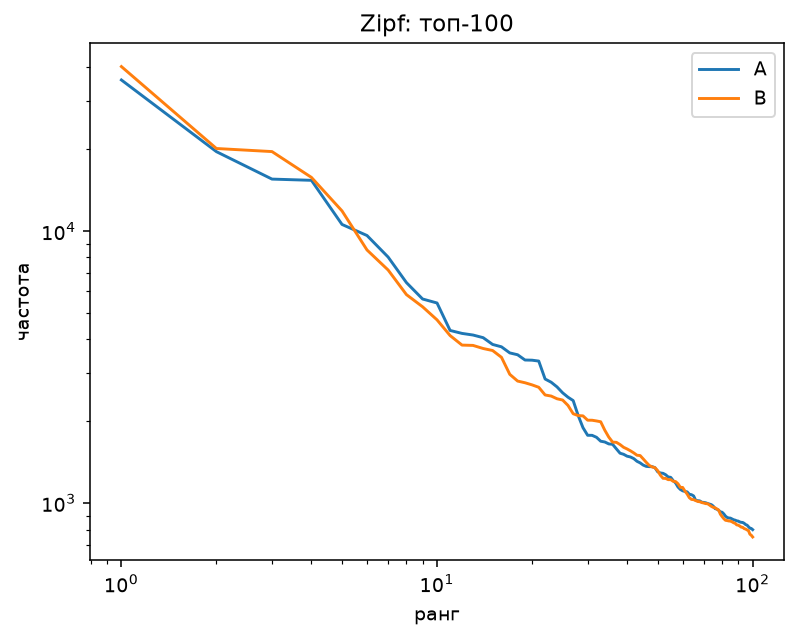

A (цифры, пунктуация): (0.0059, 0.0287)
B (цифры, пунктуация): (0.0117, 0.0271)


In [6]:
cnt_a, cnt_b = Counter(), Counter()
for t in texts_a: cnt_a.update(simple_tokenize(t))
for t in texts_b: cnt_b.update(simple_tokenize(t))

plt.figure()
for c, name in [(cnt_a, "A"), (cnt_b, "B")]:
    freqs = [f for _, f in c.most_common(100)]
    plt.loglog(range(1, len(freqs) + 1), freqs, label=name)
plt.legend(); plt.title("Zipf: топ-100"); plt.xlabel("ранг"); plt.ylabel("частота"); plt.show()

def digit_punct_share(texts):
    s = "".join(texts)
    digits = sum(ch.isdigit() for ch in s) / len(s)
    punct = sum(not ch.isalnum() and not ch.isspace() for ch in s) / len(s)
    return round(digits, 4), round(punct, 4)

print("A (цифры, пунктуация):", digit_punct_share(texts_a))
print("B (цифры, пунктуация):", digit_punct_share(texts_b))

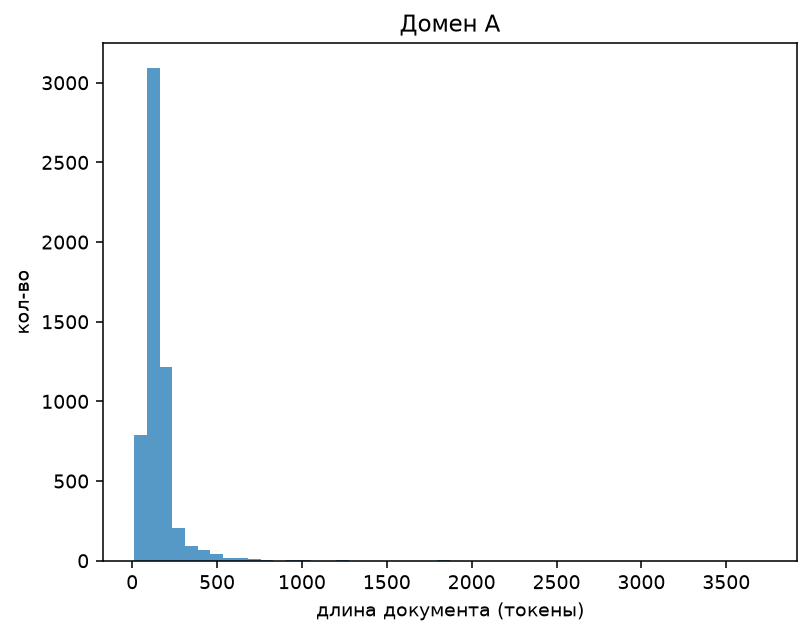

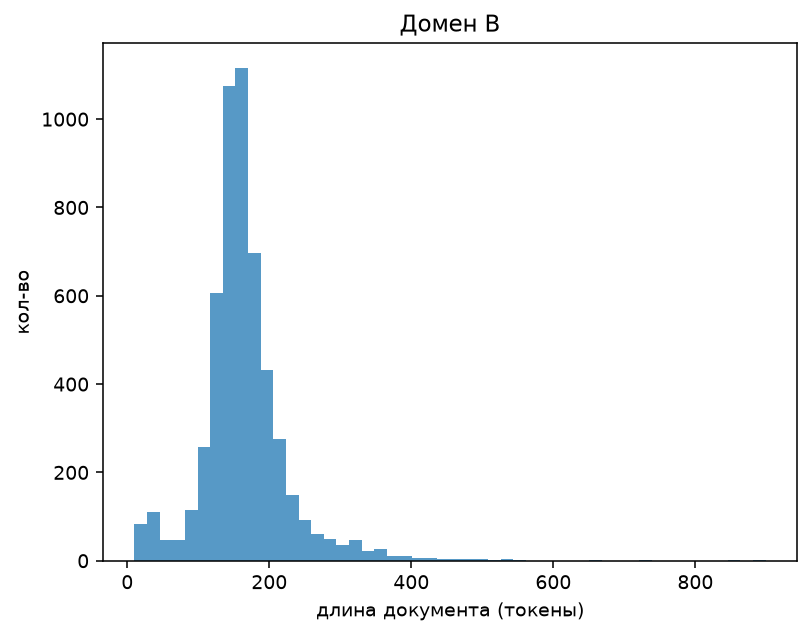

In [7]:
plot_length_hist(texts_a, "Домен A")
plot_length_hist(texts_b, "Домен B")

4. лемматизация, n-граммы, стоп-слова и сравнение важных токенов

In [8]:
import nltk
from nltk.corpus import stopwords
import pymorphy3 
from functools import lru_cache

nltk.download("stopwords", quiet=True)
ru_stop = stopwords.words("russian")

In [9]:
morph = pymorphy3.MorphAnalyzer()

@lru_cache(maxsize=None)
def lemma(w):
    return morph.parse(w)[0].normal_form

def lemmatize_text(t):
    return " ".join(lemma(w) for w in simple_tokenize(t))

texts_a_lem = [lemmatize_text(t) for t in texts_a]
texts_b_lem = [lemmatize_text(t) for t in texts_b]

pos_l, neg_l = top_log_odds_words(texts_a_lem, texts_b_lem, top_n=30, alpha=0.1)
pos_l = [(w, d) for w, d in pos_l if w not in ru_stop]
display(pd.DataFrame(pos_l, columns=["лемма", "Δ(A-B)"]))

,лемма,Δ(A-B)
0,лавров,8.130079
1,обстрел,8.098541
2,кадыров,7.920121
3,канцлер,7.900785
4,урегулирование,7.608014
5,провокация,7.565250
6,коррупция,7.559773
7,чвк,7.346330
8,генсек,7.318761
9,хамас,7.311748


5. наблюдения
- частоты слов подчиняются закону Ципфа. несколько самых частых слов дают большую часть токенов, а большинство слов в словаре встречаются всего пару раз
- после предобработки в топе остаются служебные слова, значит, стоп-слова удалены не полностью
- после лемматизации стали популярны более простые слова, не названия
- лемматизация занимает долгое время на длинных текстах без кжширования
- чем больше в тексте имён собственных и географических названий, тем сильнее сдвиг между доменами, потому что такие слова редко повторяются в других источниках

## Часть B — Наивный Байес + оценка
1) Выберите 2 автора (русский).
2) Нарежьте тексты на чанки (80–300 токенов).
3) Обучите MultinomialNB и отчитайтесь:
   - confusion matrix,
   - precision/recall/F1.
4) Покажите **top-20 важнейших токенов** на основе Δ(w).
5) добавьте лемматизацию, n-граммы, стоп-слова, и сравните важные токены.
6) Сделайте domain shift (например, проза → стихи / письма / пьесы) и опишите, что сломалось и что помогло.

1. выбор авторов

Gutenberg на момент выполнения дз был недоступен, поэтому файлы найдены вручную

Пушкин - проза - Капитанская дочка

Пушкин - поэзия - Руслан и Людмила

Лермонтов - проза - Герой нашего времени

Лермонтов - поэзия - Демон

In [10]:
import requests

In [11]:
def get_text(url):
    text = requests.get(url).text
    return text

In [12]:
pushkin_prose = get_text("https://raw.githubusercontent.com/maurry/nlp/main/Pushkin_proza.txt")
pushkin_poetry = get_text("https://raw.githubusercontent.com/maurry/nlp/main/Pushkin_poem.txt")
lerm_prose = get_text("https://raw.githubusercontent.com/maurry/nlp/main/Lermontov_proza.txt")
lerm_poetry =  get_text("https://raw.githubusercontent.com/maurry/nlp/main/Lermontov_poem.txt")

print(pushkin_prose[:200]+'\n')
print(pushkin_poetry[:200]+'\n')
print(lerm_prose[:200]+'\n')
print(lerm_poetry[:200]+'\n')


 ГЛАВА I. СЕРЖАНТ ГВАРДИИ.


 - Был бы гвардии он завтра ж капитан.
 - Того не надобно; пусть в армии послужит.
 - Изрядно сказано! пускай его потужит...
 .....................................

 Для вас, души моей царицы,
 Красавицы, для вас одних
 Времен минувших небылицы,
 В часы досугов золотых,
 Под шепот старины болтливой,
 Рукою верной я писал;
 Примите ж вы мой труд игривый!
 Н

    Михаил Лермонтов. Герой нашего времени




     Во всякой книге предисловие есть первая и вместе с тем последняя  вещь;
оно или служит объяснением цели сочинения,  или  оправданием  и  ответ

 Печальный Демон, дух изгнанья, Летал над грешною землей, И лучших дней воспоминанья Пред ним теснилися толпой; Тex дней, когда в жилище света Блистал он, чистый херувим, Когда бегущая комета Улыбкой 



2. нарезка на чанки

In [13]:
CHUNK_SIZE = 120 # меньше -> больше документов; попробуйте 80..200

def make_chunks(text: str, chunk_size: int) -> List[str]:
    toks = simple_tokenize(text)
    return chunk_tokens(toks, chunk_size=chunk_size, min_frac=0.5)

pushkin_prose_chunks = make_chunks(pushkin_prose, CHUNK_SIZE)
lerm_prose_chunks = make_chunks(lerm_prose, CHUNK_SIZE)

pushkin_poetry_chunks = make_chunks(pushkin_poetry, CHUNK_SIZE)
lerm_poetry_chunks = make_chunks(lerm_poetry, CHUNK_SIZE)

print("Чанки (проза):", len(pushkin_prose_chunks), len(lerm_prose_chunks))
print("Чанки (поэзия):", len(pushkin_poetry_chunks), len(lerm_poetry_chunks))

X_prose = pushkin_prose_chunks + lerm_prose_chunks
y_prose = np.array([0]*len(pushkin_prose_chunks) + [1]*len(lerm_prose_chunks))

X_poetry = pushkin_poetry_chunks + lerm_poetry_chunks
y_poetry = np.array([0]*len(pushkin_poetry_chunks) + [1]*len(lerm_poetry_chunks))

author_names = ["Pushkin", "Lermontov"]

Чанки (проза): 279 353
Чанки (поэзия): 99 40


3. MultinomialNB

In [14]:
# Train/Valid split (внутридоменный: проза → проза)

Xtr, Xva, ytr, yva = train_test_split(
    X_prose, y_prose, test_size=0.25, random_state=RANDOM_STATE, stratify=y_prose
)

print("Train chunks:", len(Xtr), "Valid chunks:", len(Xva))

Train chunks: 474 Valid chunks: 158


In [15]:
# B4-baseline) Multinomial NB (counts) — без предобработки

nb_counts_base = Pipeline([
    ("vec", CountVectorizer(
        # всё по умолчанию:
        # lowercase=True, token_pattern=...,
        # stop_words=None, min_df=1, max_df=1.0, ngram_range=(1,1)
    )),
    ("nb", MultinomialNB(alpha=0.1)),
])

nb_counts_base.fit(Xtr, ytr)
pred_va_base = nb_counts_base.predict(Xva)

print("BASE In-domain (PROSE→PROSE) accuracy:", accuracy_score(yva, pred_va_base))
print(classification_report(yva, pred_va_base, target_names=author_names))
print("Confusion matrix:\n", confusion_matrix(yva, pred_va_base))


BASE In-domain (PROSE→PROSE) accuracy: 1.0
              precision    recall  f1-score   support

     Pushkin       1.00      1.00      1.00        70
   Lermontov       1.00      1.00      1.00        88

    accuracy                           1.00       158
   macro avg       1.00      1.00      1.00       158
weighted avg       1.00      1.00      1.00       158

Confusion matrix:
 [[70  0]
 [ 0 88]]


По confusion matrix:
- Пушкин/Пушкина TP модель предсказала 70 раз верно, Пушкин/Лермонтов FN 0 раз неверно
- Лермонтов/Пушкин FP модель предсказала 0 раз неверно, Лермонтов/Лермонтов TN 81 раз верно

precision = TP / (TP + FP) = 1.00

recall = TP / (TP + FN) = 1.00


F1 = 2 · precision · recall / (precision + recall) = 1.00

4. top-20 важнейших токенов на основе Δ(w)

In [16]:
#  Самые важные токены для NB: Δ(w)=logP(w|Pushkin)-logP(w|Lermontov)

vec = nb_counts_base.named_steps["vec"]
clf = nb_counts_base.named_steps["nb"]
feature_names = np.array(vec.get_feature_names_out())

delta = clf.feature_log_prob_[0] - clf.feature_log_prob_[1]

top_n = 30
top_pushkin = np.argsort(-delta)[:top_n]
top_lerm = np.argsort(delta)[:top_n]  # самые отрицательные

df_pushkin = pd.DataFrame({"token": feature_names[top_pushkin], "Δ": delta[top_pushkin]})
df_lerm = pd.DataFrame({"token": feature_names[top_lerm], "Δ": delta[top_lerm]})

print("Топ-токены для Пушкина")
display(df_pushkin)
print("Топ-токены для Лермонтова")
display(df_lerm)


Топ-токены для Пушкина


,token,Δ
0,пугачев,6.818253
1,марья,6.804286
2,ивановна,6.790122
3,всё,6.549348
4,савельич,6.549348
5,швабрин,6.231575
6,андреич,6.126492
7,матушка,6.098400
8,кузмич,5.944724
9,пугачева,5.839732


Топ-токены для Лермонтова


,token,Δ
0,грушницкий,-6.225416
1,печорин,-5.805019
2,княжна,-5.533827
3,доктор,-5.400741
4,максим,-5.400741
5,едва,-5.326907
6,больше,-5.326907
7,нынче,-5.247183
8,штабс,-5.114244
9,казбич,-5.114244


5. лемматизация, n-граммы, стоп-слова и сравнить важные токены

In [17]:
@lru_cache(maxsize=200_000)
def lemma_cached(w: str) -> str:
    return morph.parse(w)[0].normal_form

def tokenize_lemmas(text: str) -> List[str]:
    tokens = []
    for w in simple_tokenize(text.lower()):
        if w in ru_stop:
            continue
        lemma = lemma_cached(w)
        if lemma in ru_stop:
            continue
        tokens.append(lemma)
    return tokens

vec = CountVectorizer(
    tokenizer=tokenize_lemmas,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9
)

In [18]:
# B4) Multinomial NB (counts) + улучшенная предобработка

nb_counts = Pipeline([
    ("vec", vec),
    ("nb", MultinomialNB(alpha=0.1)),
])

nb_counts.fit(Xtr, ytr)
pred_va = nb_counts.predict(Xva)

print("In-domain (PROSE→PROSE) accuracy:", accuracy_score(yva, pred_va))
print(classification_report(yva, pred_va, target_names=author_names))
print("Confusion matrix:\n", confusion_matrix(yva, pred_va))


In-domain (PROSE→PROSE) accuracy: 0.9936708860759493
              precision    recall  f1-score   support

     Pushkin       1.00      0.99      0.99        70
   Lermontov       0.99      1.00      0.99        88

    accuracy                           0.99       158
   macro avg       0.99      0.99      0.99       158
weighted avg       0.99      0.99      0.99       158

Confusion matrix:
 [[69  1]
 [ 0 88]]


In [19]:
#  Самые важные токены для NB: Δ(w)=logP(w|Pushkin)-logP(w|Lermontov)

vec = nb_counts.named_steps["vec"]
clf = nb_counts.named_steps["nb"]
feature_names = np.array(vec.get_feature_names_out())

delta = clf.feature_log_prob_[0] - clf.feature_log_prob_[1]

top_n = 30
top_pushkin = np.argsort(-delta)[:top_n]
top_lerm = np.argsort(delta)[:top_n]  # самые отрицательные

df_pushkin = pd.DataFrame({"token": feature_names[top_pushkin], "Δ": delta[top_pushkin]})
df_lerm = pd.DataFrame({"token": feature_names[top_lerm], "Δ": delta[top_lerm]})

print("Топ-токены для Пушкина")
display(df_pushkin)
print("Топ-токены для Лермонтова")
display(df_lerm)


Топ-токены для Пушкина


,token,Δ
0,пугачёв,7.329838
1,иванович,7.322181
2,марья,7.069987
3,марья иванович,7.050007
4,савельич,6.920934
5,швабрин,6.811867
6,всё,6.463027
7,матушка,6.284690
8,кузмич,6.169885
9,андреевич,6.169885


Топ-токены для Лермонтова


,token,Δ
0,грушницкий,-6.652213
1,княжна,-6.456708
2,печорин,-6.327217
3,максим максимович,-5.817415
4,максим,-5.817415
5,княгиня,-5.709494
6,доктор,-5.680590
7,казбич,-5.522031
8,едва,-5.413228
9,слепой,-5.374161


6. Domain shift

In [20]:
# B6) Domain shift: обучаемся на прозе, тестируемся на поэзии

pred_poetry = nb_counts.predict(X_poetry)

print("Domain shift (PROSE→POETRY) accuracy:", accuracy_score(y_poetry, pred_poetry))
print(classification_report(y_poetry, pred_poetry, target_names=author_names))
print("Confusion matrix:\n", confusion_matrix(y_poetry, pred_poetry))


Domain shift (PROSE→POETRY) accuracy: 0.33093525179856115
              precision    recall  f1-score   support

     Pushkin       1.00      0.06      0.11        99
   Lermontov       0.30      1.00      0.46        40

    accuracy                           0.33       139
   macro avg       0.65      0.53      0.29       139
weighted avg       0.80      0.33      0.21       139

Confusion matrix:
 [[ 6 93]
 [ 0 40]]


По confusion matrix:
- Пушкин/Пушкина TP модель предсказала 6 раз верно, Пушкин/Лермонтов FN 93 раз неверно
- Лермонтов/Пушкин FP модель предсказала 0 раз неверно, Лермонтов/Лермонтов TN 40 раз верно

precision = TP / (TP + FP) = 1.00

recall = TP / (TP + FN) = 0.06


F1 = 2 · precision · recall / (precision + recall) = 0.11

recall Модель стала хуже угадывать Пушкина, чем Лермонтова на всех элементах класса

модель начала Пушкина принимать за Лермонтова
